In [1]:
# Core libraries
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Machine-learning tools
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    auc,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_val_score,
    learning_curve,
)
from sklearn.preprocessing import (
    LabelEncoder,
    label_binarize,
)

In [2]:
# Trim first-level mixture events and retain their
# corresponding secondary events.

# DATA_DIR = Path(".")
DATA_DIR = Path(
    "/Volumes/JAEONCHO/ADIC-AA/g_CD data"
)

EVENT_DIR = DATA_DIR / "events_g_CD_mix"
SUB_EVENT_DIR = DATA_DIR / "sub_events_g_CD_mix"

TRIM_EVENT_DIR = (
    DATA_DIR / "trim_events_g_CD_mix"
)

TRIM_SUB_EVENT_DIR = (
    DATA_DIR / "trim_sub_events_g_CD_mix"
)

TRIM_EVENT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

TRIM_SUB_EVENT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# Remove files generated by previous runs so that stale
# files are not retained.
for output_file in TRIM_EVENT_DIR.glob("*.csv"):
    output_file.unlink()

for output_file in TRIM_SUB_EVENT_DIR.glob("*.csv"):
    output_file.unlink()

retained_event_count = 0
retained_sub_event_count = 0
skipped_recordings = []

for event_file in sorted(
    EVENT_DIR.glob("*.csv")
):
    events = pd.read_csv(
        event_file
    )

    density = (
        events["num_sub_events"]
        / events["dwell_time_us"]
    )

    log_density = np.log(
        density
    )

    median_log_density = np.median(
        log_density
    )

    mad = np.median(
        np.abs(
            log_density
            - median_log_density
        )
    )

    if mad == 0 or not np.isfinite(mad):
        skipped_recordings.append(
            event_file.name
        )

        print(
            f"Skipped {event_file.name}: "
            "MAD could not be calculated because the "
            "recording contained insufficient event "
            "variation."
        )

        continue

    robust_z = (
        0.6745
        * (
            log_density
            - median_log_density
        )
        / mad
    )

    trimmed_events = events.loc[
        np.abs(robust_z) <= 3
    ].copy()

    if trimmed_events.empty:
        print(
            f"Skipped {event_file.name}: "
            "no first-level events remained after "
            "trimming."
        )

        continue

    trimmed_event_path = (
        TRIM_EVENT_DIR
        / event_file.name
    )

    trimmed_events.to_csv(
        trimmed_event_path,
        index=False,
    )

    retained_event_count += len(
        trimmed_events
    )

    sub_event_file = (
        SUB_EVENT_DIR
        / f"{event_file.stem}_sub.csv"
    )

    if not sub_event_file.exists():
        print(
            f"Warning: no matching secondary-event "
            f"file for {event_file.name}"
        )

        continue

    sub_events = pd.read_csv(
        sub_event_file
    )

    keep_sub_event = np.zeros(
        len(sub_events),
        dtype=bool,
    )

    for _, event in trimmed_events.iterrows():
        keep_sub_event |= (
            (
                sub_events["sub_start_time_s"]
                >= event["start_time_s"]
            )
            & (
                sub_events["sub_end_time_s"]
                <= event["end_time_s"]
            )
        )

    trimmed_sub_events = sub_events.loc[
        keep_sub_event
    ].copy()

    if trimmed_sub_events.empty:
        print(
            f"Warning: no secondary events remained "
            f"for {event_file.name}"
        )

        continue

    trimmed_sub_event_path = (
        TRIM_SUB_EVENT_DIR
        / sub_event_file.name
    )

    trimmed_sub_events.to_csv(
        trimmed_sub_event_path,
        index=False,
    )

    retained_sub_event_count += len(
        trimmed_sub_events
    )

print()

print(
    f"Retained {retained_event_count:,} "
    "first-level events."
)

print(
    f"Retained {retained_sub_event_count:,} "
    "secondary events."
)

print(
    f"Skipped {len(skipped_recordings)} "
    "recordings because MAD could not be calculated."
)


Retained 8,335 first-level events.
Retained 94,867 secondary events.
Skipped 0 recordings because MAD could not be calculated.


In [3]:
# Assemble the mixture dataset from trimmed events,
# secondary events, and open-pore baseline measurements.

BASELINE_DIR = (
    DATA_DIR
    / "final_baseline_info_g_CD_mix"
)

MIXTURE_CLASSES = [
    "DP",
    "DT",
    "DY",
    "FP",
    "GH",
    "GQ",
    "HM",
    "HN",
    "LD",
    "LE",
    "LI",
    "LW",
    "MD",
    "MV",
    "RV",
    "SA",
    "SD",
    "SL",
    "TV",
    "VD",
]

assembled_datasets = []

for sub_event_file in sorted(
    TRIM_SUB_EVENT_DIR.glob("*.csv")
):
    recording_id = (
        sub_event_file.stem.removesuffix("_sub")
    )

    event_file = (
        TRIM_EVENT_DIR
        / f"{recording_id}.csv"
    )

    baseline_file = (
        BASELINE_DIR
        / f"{recording_id}_final.csv"
    )

    if not event_file.exists():
        raise FileNotFoundError(
            f"Missing trimmed event file: "
            f"{event_file.name}"
        )

    if not baseline_file.exists():
        raise FileNotFoundError(
            f"Missing baseline file: "
            f"{baseline_file.name}"
        )

    sub_events = pd.read_csv(
        sub_event_file
    )

    first_level_events = pd.read_csv(
        event_file
    )

    baseline_data = pd.read_csv(
        baseline_file
    )

    if baseline_data.empty:
        raise ValueError(
            f"Baseline file is empty: "
            f"{baseline_file.name}"
        )

    open_pore_rms = (
        baseline_data["rms"].iloc[0]
    )

    mixture_name = recording_id[:2]

    if mixture_name not in MIXTURE_CLASSES:
        raise ValueError(
            f"Unexpected mixture label "
            f"{mixture_name} in "
            f"{sub_event_file.name}"
        )

    matched_rows = []

    for _, sub_event in sub_events.iterrows():
        parent_event = first_level_events.loc[
            (
                first_level_events["start_time_s"]
                <= sub_event["sub_start_time_s"]
            )
            & (
                first_level_events["end_time_s"]
                >= sub_event["sub_end_time_s"]
            )
        ]

        if parent_event.empty:
            continue

        parent_event = parent_event.iloc[0]

        event_id = (
            f"{recording_id}_"
            f"{int(parent_event['event_index'])}"
        )

        matched_rows.append({
            "sub_pre_interaction_current":
                sub_event[
                    "sub_pre_interaction_current"
                ],

            "sub_post_interaction_current":
                sub_event[
                    "sub_post_interaction_current"
                ],

            # I1
            "first_level_current":
                sub_event["sub_mode_baseline"],

            # σ1
            "first_level_stdev":
                parent_event["blockage_stdev"],

            # σ0
            "open_pore_rms":
                open_pore_rms,

            "dwell_time_us":
                parent_event["dwell_time_us"],

            "num_sub_events":
                parent_event["num_sub_events"],

            # Parent first-level blockage
            "event_id":
                event_id,

            # Single-pore recording
            "dataset_id":
                recording_id,

            "mixture":
                mixture_name,
        })

    if matched_rows:
        assembled_datasets.append(
            pd.DataFrame(matched_rows)
        )

if not assembled_datasets:
    raise ValueError(
        "No matched secondary events were found."
    )

df = pd.concat(
    assembled_datasets,
    ignore_index=True,
)

df = (
    df.loc[
        df["mixture"].isin(
            MIXTURE_CLASSES
        )
    ]
    .reset_index(drop=True)
)

if df.isna().any().any():
    missing_columns = (
        df.columns[
            df.isna().any()
        ]
        .tolist()
    )

    raise ValueError(
        f"Missing values detected in: "
        f"{missing_columns}"
    )

if (df["open_pore_rms"] <= 0).any():
    raise ValueError(
        "All open-pore RMS values must be positive."
    )

print(
    f"Mixture classes: "
    f"{df['mixture'].nunique()}"
)

print(
    f"Secondary events: "
    f"{len(df):,}"
)

print(
    f"First-level events: "
    f"{df['event_id'].nunique():,}"
)

print(
    f"Single-pore recordings: "
    f"{df['dataset_id'].nunique():,}"
)

display(df.head())

Mixture classes: 20
Secondary events: 94,867
First-level events: 7,052
Single-pore recordings: 106


,sub_pre_interaction_current,sub_post_interaction_current,first_level_current,first_level_stdev,open_pore_rms,dwell_time_us,num_sub_events,event_id,dataset_id,mixture
0,101.623535,120.849610,128.78418,12.573928,4.952532,12050.0,5.0,DP_g_CD_250829__0001_0,DP_g_CD_250829__0001,DP
1,46.081543,117.255320,128.78418,12.573928,4.952532,12050.0,5.0,DP_g_CD_250829__0001_0,DP_g_CD_250829__0001,DP
2,107.879640,115.173340,128.78418,12.573928,4.952532,12050.0,5.0,DP_g_CD_250829__0001_0,DP_g_CD_250829__0001,DP
3,106.658936,115.478516,128.78418,12.573928,4.952532,12050.0,5.0,DP_g_CD_250829__0001_0,DP_g_CD_250829__0001,DP
4,107.116700,117.340090,128.78418,12.573928,4.952532,12050.0,5.0,DP_g_CD_250829__0001_0,DP_g_CD_250829__0001,DP


In [4]:
# Encode mixture labels, split by parent first-level
# blockage, and construct the four classifier features.

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FEATURE_NAMES = [
    "Baseline Ratio",
    "Z Score",
    "Per-event Impact",
    "Per-time Impact",
]

mixture_label_encoder = LabelEncoder()
mixture_label_encoder.fit(
    MIXTURE_CLASSES
)

label_mapping = {
    class_name: int(encoded_label)
    for class_name, encoded_label
    in zip(
        mixture_label_encoder.classes_,
        mixture_label_encoder.transform(
            mixture_label_encoder.classes_
        ),
    )
}

print(
    "Label mapping:",
    label_mapping,
)

# Each event_id represents one parent first-level blockage.
event_table = (
    df[
        [
            "event_id",
            "dataset_id",
            "mixture",
        ]
    ]
    .drop_duplicates(subset="event_id")
    .sort_values(
        [
            "mixture",
            "event_id",
        ]
    )
    .reset_index(drop=True)
)

event_validation = (
    df.groupby("event_id")
    .agg(
        mixture_count=(
            "mixture",
            "nunique",
        ),
        dataset_count=(
            "dataset_id",
            "nunique",
        ),
    )
)

if (
    (
        event_validation["mixture_count"]
        != 1
    ).any()
    or (
        event_validation["dataset_count"]
        != 1
    ).any()
):
    raise ValueError(
        "Each event_id must correspond to one mixture "
        "class and one single-pore recording."
    )

# Deterministic 60:20:20 target split within each class.
rng = np.random.default_rng(42)
split_assignment = {}

for mixture_name in MIXTURE_CLASSES:
    mixture_event_ids = (
        event_table.loc[
            event_table["mixture"]
            == mixture_name,
            "event_id",
        ]
        .sort_values()
        .to_numpy()
    )

    mixture_event_ids = rng.permutation(
        mixture_event_ids
    )

    number_of_events = len(
        mixture_event_ids
    )

    number_train = max(
        1,
        int(
            np.floor(
                0.60 * number_of_events
            )
        ),
    )

    number_validation = max(
        1,
        int(
            np.floor(
                0.20 * number_of_events
            )
        ),
    )

    if (
        number_train
        + number_validation
        >= number_of_events
    ):
        number_validation = max(
            0,
            number_of_events
            - number_train
            - 1,
        )

    train_event_ids = (
        mixture_event_ids[:number_train]
    )

    validation_event_ids = (
        mixture_event_ids[
            number_train:
            number_train + number_validation
        ]
    )

    test_event_ids = (
        mixture_event_ids[
            number_train
            + number_validation:
        ]
    )

    for event_id in train_event_ids:
        split_assignment[event_id] = "train"

    for event_id in validation_event_ids:
        split_assignment[event_id] = "validation"

    for event_id in test_event_ids:
        split_assignment[event_id] = "test"

# Every recording must contribute at least one training
# event because recording-level aggregate features are
# calculated from training observations only.
for dataset_id in sorted(
    event_table["dataset_id"].unique()
):
    recording_event_ids = (
        event_table.loc[
            event_table["dataset_id"]
            == dataset_id,
            "event_id",
        ]
        .sort_values()
        .tolist()
    )

    has_training_event = any(
        split_assignment[event_id]
        == "train"
        for event_id in recording_event_ids
    )

    if not has_training_event:
        event_to_move = (
            recording_event_ids[0]
        )

        split_assignment[
            event_to_move
        ] = "train"

df["split"] = df["event_id"].map(
    split_assignment
)

if df["split"].isna().any():
    raise ValueError(
        "Some secondary events were not assigned "
        "to a split."
    )

train_mask = df["split"] == "train"

validation_mask = (
    df["split"] == "validation"
)

test_mask = df["split"] == "test"

# Calculate recording-level aggregate values using
# training observations only.
training_rows = df.loc[
    train_mask
].copy()

training_secondary_event_count = (
    training_rows
    .groupby("dataset_id")
    .size()
    .rename(
        "training_secondary_event_count"
    )
)

training_first_level_dwell_time = (
    training_rows[
        [
            "dataset_id",
            "event_id",
            "dwell_time_us",
        ]
    ]
    .drop_duplicates(subset="event_id")
    .groupby("dataset_id")[
        "dwell_time_us"
    ]
    .sum()
    .rename(
        "training_first_level_dwell_time"
    )
)

training_aggregates = pd.concat(
    [
        training_secondary_event_count,
        training_first_level_dwell_time,
    ],
    axis=1,
)

training_aggregates[
    "training_event_frequency"
] = (
    training_aggregates[
        "training_secondary_event_count"
    ]
    / training_aggregates[
        "training_first_level_dwell_time"
    ]
)

if (
    training_aggregates.isna().any().any()
    or (
        training_aggregates[
            "training_secondary_event_count"
        ]
        <= 0
    ).any()
    or (
        training_aggregates[
            "training_first_level_dwell_time"
        ]
        <= 0
    ).any()
    or (
        training_aggregates[
            "training_event_frequency"
        ]
        <= 0
    ).any()
):
    raise ValueError(
        "Invalid training-derived aggregate values "
        "detected."
    )

feature_source = df.copy()

for aggregate_column in [
    "training_secondary_event_count",
    "training_first_level_dwell_time",
    "training_event_frequency",
]:
    feature_source[
        aggregate_column
    ] = feature_source["dataset_id"].map(
        training_aggregates[
            aggregate_column
        ]
    )

aggregate_columns = [
    "training_secondary_event_count",
    "training_first_level_dwell_time",
    "training_event_frequency",
]

if (
    feature_source[
        aggregate_columns
    ]
    .isna()
    .any()
    .any()
):
    missing_recordings = (
        feature_source.loc[
            feature_source[
                aggregate_columns
            ]
            .isna()
            .any(axis=1),
            "dataset_id",
        ]
        .unique()
        .tolist()
    )

    raise ValueError(
        "No training-derived aggregate values for: "
        f"{missing_recordings}"
    )

# Construct the four classifier features.
feature_source["Baseline Ratio"] = (
    feature_source[
        "sub_post_interaction_current"
    ]
    / feature_source[
        "first_level_current"
    ]
)

# Z score normalized by open-pore noise σ0.
feature_source["Z Score"] = (
    (
        feature_source[
            "sub_post_interaction_current"
        ]
        - feature_source[
            "first_level_current"
        ]
    )
    / feature_source[
        "open_pore_rms"
    ]
)

feature_source["Per-event Impact"] = (
    feature_source["Z Score"] ** 2
    / feature_source[
        "training_secondary_event_count"
    ]
)

feature_source["Per-time Impact"] = (
    feature_source["Z Score"] ** 2
    / feature_source[
        "training_event_frequency"
    ]
)

if not np.isfinite(
    feature_source[
        FEATURE_NAMES
    ].to_numpy()
).all():
    raise ValueError(
        "Nonfinite values detected in "
        "classifier features."
    )

X_train = (
    feature_source.loc[
        train_mask,
        FEATURE_NAMES,
    ]
    .copy()
    .reset_index(drop=True)
)

X_val = (
    feature_source.loc[
        validation_mask,
        FEATURE_NAMES,
    ]
    .copy()
    .reset_index(drop=True)
)

X_test = (
    feature_source.loc[
        test_mask,
        FEATURE_NAMES,
    ]
    .copy()
    .reset_index(drop=True)
)

y_train = mixture_label_encoder.transform(
    feature_source.loc[
        train_mask,
        "mixture",
    ]
)

y_val = mixture_label_encoder.transform(
    feature_source.loc[
        validation_mask,
        "mixture",
    ]
)

y_test = mixture_label_encoder.transform(
    feature_source.loc[
        test_mask,
        "mixture",
    ]
)

groups_train = (
    feature_source.loc[
        train_mask,
        "event_id",
    ]
    .reset_index(drop=True)
    .to_numpy()
)

split_assignment_df = (
    feature_source[
        [
            "event_id",
            "dataset_id",
            "mixture",
            "split",
        ]
    ]
    .drop_duplicates(subset="event_id")
    .sort_values(
        [
            "mixture",
            "event_id",
        ]
    )
    .reset_index(drop=True)
)

split_assignment_df.to_csv(
    OUTPUT_DIR
    / "mixture_classifier_split_assignment.csv",
    index=False,
)

joblib.dump(
    mixture_label_encoder,
    OUTPUT_DIR
    / "mixture_classifier_label_encoder.joblib",
)

print(
    f"Training observations: "
    f"{len(X_train):,}"
)

print(
    f"Validation observations: "
    f"{len(X_val):,}"
)

print(
    f"Test observations: "
    f"{len(X_test):,}"
)

print(
    "\nParent first-level events by split:"
)

print(
    split_assignment_df["split"]
    .value_counts()
    .reindex(
        [
            "train",
            "validation",
            "test",
        ],
        fill_value=0,
    )
)

Label mapping: {np.str_('DP'): 0, np.str_('DT'): 1, np.str_('DY'): 2, np.str_('FP'): 3, np.str_('GH'): 4, np.str_('GQ'): 5, np.str_('HM'): 6, np.str_('HN'): 7, np.str_('LD'): 8, np.str_('LE'): 9, np.str_('LI'): 10, np.str_('LW'): 11, np.str_('MD'): 12, np.str_('MV'): 13, np.str_('RV'): 14, np.str_('SA'): 15, np.str_('SD'): 16, np.str_('SL'): 17, np.str_('TV'): 18, np.str_('VD'): 19}
Training observations: 56,707
Validation observations: 18,803
Test observations: 19,357

Parent first-level events by split:
split
train         4222
validation    1401
test          1429
Name: count, dtype: int64


In [5]:
# Train the mixture random forest classifier.

mixture_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced_subsample",
    n_jobs=-1,
)

mixture_classifier.fit(
    X_train,
    y_train,
)

MODEL_PATH = (
    OUTPUT_DIR
    / "mixture_classifier.joblib"
)

joblib.dump(
    mixture_classifier,
    MODEL_PATH,
)

print(
    f"Model saved to: "
    f"{MODEL_PATH.resolve()}"
)

Model saved to: /Users/jaeoncho/Desktop/lab/gcd_aa/codes/jupyter/ML_gCD/outputs/mixture_classifier.joblib


In [6]:
# Evaluate the mixture classifier.

grouped_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

cv_scores = cross_val_score(
    clone(mixture_classifier),
    X_train,
    y_train,
    groups=groups_train,
    cv=grouped_cv,
    scoring="accuracy",
    n_jobs=-1,
)

y_test_pred = mixture_classifier.predict(
    X_test
)

y_test_proba = (
    mixture_classifier.predict_proba(
        X_test
    )
)

test_accuracy = accuracy_score(
    y_test,
    y_test_pred,
)

validation_accuracy = (
    mixture_classifier.score(
        X_val,
        y_val,
    )
)

f1_micro = f1_score(
    y_test,
    y_test_pred,
    average="micro",
)

f1_macro = f1_score(
    y_test,
    y_test_pred,
    average="macro",
)

precision_micro = precision_score(
    y_test,
    y_test_pred,
    average="micro",
    zero_division=0,
)

recall_micro = recall_score(
    y_test,
    y_test_pred,
    average="micro",
    zero_division=0,
)

auc_macro = roc_auc_score(
    y_test,
    y_test_proba,
    multi_class="ovr",
    average="macro",
)

auc_micro = roc_auc_score(
    y_test,
    y_test_proba,
    multi_class="ovr",
    average="micro",
)

metrics_summary = pd.DataFrame({
    "metric": [
        "test_accuracy",
        "validation_accuracy",
        "cross_validation_mean",
        "cross_validation_std",
        "f1_micro",
        "f1_macro",
        "precision_micro",
        "recall_micro",
        "auc_macro",
        "auc_micro",
    ],
    "value": [
        test_accuracy,
        validation_accuracy,
        cv_scores.mean(),
        cv_scores.std(),
        f1_micro,
        f1_macro,
        precision_micro,
        recall_micro,
        auc_macro,
        auc_micro,
    ],
})

cv_results = pd.DataFrame({
    "fold": np.arange(
        1,
        len(cv_scores) + 1,
    ),
    "accuracy": cv_scores,
})

test_predictions = pd.DataFrame({
    "actual_encoded": y_test,
    "predicted_encoded": y_test_pred,
})

test_predictions["actual"] = (
    mixture_label_encoder.inverse_transform(
        y_test
    )
)

test_predictions["predicted"] = (
    mixture_label_encoder.inverse_transform(
        y_test_pred
    )
)

metrics_summary.to_csv(
    OUTPUT_DIR
    / "mixture_classifier_metrics.csv",
    index=False,
)

cv_results.to_csv(
    OUTPUT_DIR
    / "mixture_classifier_cross_validation.csv",
    index=False,
)

test_predictions.to_csv(
    OUTPUT_DIR
    / "mixture_classifier_test_predictions.csv",
    index=False,
)

display(metrics_summary)
display(cv_results)

,metric,value
0,test_accuracy,0.949631
1,validation_accuracy,0.963463
2,cross_validation_mean,0.937170
3,cross_validation_std,0.022339
4,f1_micro,0.949631
5,f1_macro,0.945169
6,precision_micro,0.949631
7,recall_micro,0.949631
8,auc_macro,0.994406
9,auc_micro,0.996894


,fold,accuracy
0,1,0.920642
1,2,0.950346
2,3,0.955678
3,4,0.901388
4,5,0.957796


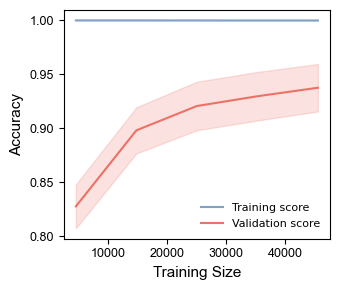

In [7]:
# Plot the grouped learning curve.

train_sizes, train_scores, validation_scores = (
    learning_curve(
        estimator=clone(mixture_classifier),
        X=X_train,
        y=y_train,
        groups=groups_train,
        cv=grouped_cv,
        train_sizes=np.linspace(
            0.1,
            1.0,
            5,
        ),
        scoring="accuracy",
        shuffle=True,
        random_state=42,
        n_jobs=-1,
    )
)

training_mean = train_scores.mean(axis=1)
training_std = train_scores.std(axis=1)

validation_mean = (
    validation_scores.mean(axis=1)
)

validation_std = (
    validation_scores.std(axis=1)
)

learning_curve_data = pd.DataFrame({
    "training_size": train_sizes,
    "training_accuracy_mean": training_mean,
    "training_accuracy_std": training_std,
    "validation_accuracy_mean": validation_mean,
    "validation_accuracy_std": validation_std,
})

learning_curve_data.to_csv(
    OUTPUT_DIR
    / "mixture_classifier_learning_curve.csv",
    index=False,
)

plt.figure(figsize=(3.5, 3))

plt.plot(
    train_sizes,
    training_mean,
    color="#80A2C5",
    linewidth=1.5,
    label="Training score",
)

plt.fill_between(
    train_sizes,
    training_mean - training_std,
    training_mean + training_std,
    color="#80A2C5",
    alpha=0.20,
)

plt.plot(
    train_sizes,
    validation_mean,
    color="#EC7166",
    linewidth=1.5,
    label="Validation score",
)

plt.fill_between(
    train_sizes,
    validation_mean - validation_std,
    validation_mean + validation_std,
    color="#EC7166",
    alpha=0.20,
)

plt.xlabel(
    "Training Size",
    fontsize=11,
    fontfamily="Arial",
)

plt.ylabel(
    "Accuracy",
    fontsize=11,
    fontfamily="Arial",
)

plt.xticks(
    fontsize=9,
    fontfamily="Arial",
)

plt.yticks(
    fontsize=9,
    fontfamily="Arial",
)

plt.legend(
    fontsize=8,
    frameon=False,
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    / "mixture_classifier_learning_curve.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

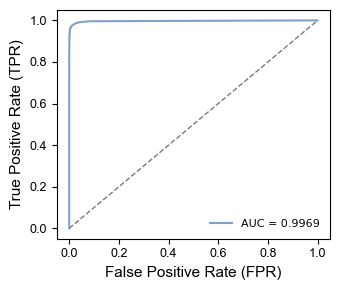

In [8]:
# Plot the micro-averaged ROC curve.

class_order = MIXTURE_CLASSES

class_order_encoded = (
    mixture_label_encoder.transform(
        class_order
    )
)

probability_column_indices = [
    np.where(
        mixture_classifier.classes_
        == encoded_class
    )[0][0]
    for encoded_class
    in class_order_encoded
]

ordered_test_proba = y_test_proba[
    :,
    probability_column_indices,
]

y_test_binary = label_binarize(
    y_test,
    classes=class_order_encoded,
)

micro_fpr, micro_tpr, _ = roc_curve(
    y_test_binary.ravel(),
    ordered_test_proba.ravel(),
)

micro_roc_auc = auc(
    micro_fpr,
    micro_tpr,
)

roc_curve_data = pd.DataFrame({
    "false_positive_rate":
        micro_fpr,

    "true_positive_rate":
        micro_tpr,
})

roc_curve_data.to_csv(
    OUTPUT_DIR
    / "mixture_classifier_ROC_curve.csv",
    index=False,
)

plt.figure(figsize=(3.5, 3))

plt.plot(
    micro_fpr,
    micro_tpr,
    color="#80A2C5",
    linewidth=1.5,
    label=f"AUC = {micro_roc_auc:.4f}",
)

plt.plot(
    [0, 1],
    [0, 1],
    color="#7A7A7A",
    linestyle="--",
    linewidth=1,
)

plt.xlabel(
    "False Positive Rate (FPR)",
    fontsize=11,
    fontfamily="Arial",
)

plt.ylabel(
    "True Positive Rate (TPR)",
    fontsize=11,
    fontfamily="Arial",
)

plt.xticks(
    fontsize=9,
    fontfamily="Arial",
)

plt.yticks(
    fontsize=9,
    fontfamily="Arial",
)

plt.legend(
    loc="lower right",
    fontsize=8,
    frameon=False,
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    / "mixture_classifier_ROC_curve.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

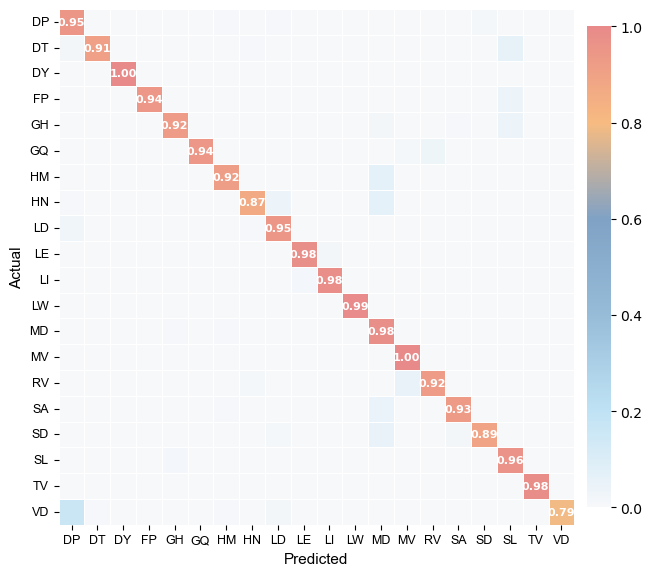

In [9]:
# Plot the normalized mixture confusion matrix.

from matplotlib.colors import LinearSegmentedColormap

class_order = MIXTURE_CLASSES

class_order_encoded = (
    mixture_label_encoder.transform(
        class_order
    )
)

confusion_mtx = confusion_matrix(
    y_test,
    y_test_pred,
    labels=class_order_encoded,
)

# Normalize each actual class by its row total.
confusion_mtx_normalized = np.divide(
    confusion_mtx.astype(float),
    confusion_mtx.sum(
        axis=1,
        keepdims=True,
    ),
    out=np.zeros_like(
        confusion_mtx,
        dtype=float,
    ),
    where=(
        confusion_mtx.sum(
            axis=1,
            keepdims=True,
        )
        != 0
    ),
)

confusion_matrix_data = pd.DataFrame(
    confusion_mtx_normalized,
    index=class_order,
    columns=class_order,
)

confusion_matrix_data.to_csv(
    OUTPUT_DIR
    / "mixture_classifier_confusion_matrix.csv"
)

paper_warm = (
    LinearSegmentedColormap.from_list(
        "paper_warm",
        [
            "#F7F8FA",
            "#BFE2F4",
            "#96BCD8",
            "#80A2C5",
            "#F7BB81",
            "#E88A8A",
        ],
        N=256,
    )
)

# Display values only on the diagonal.
annotations = np.full(
    confusion_mtx_normalized.shape,
    "",
    dtype=object,
)

for index in range(
    len(class_order)
):
    annotations[index, index] = (
        f"{confusion_mtx_normalized[index, index]:.2f}"
    )

plt.figure(figsize=(7, 6))

ax = sns.heatmap(
    confusion_mtx_normalized,
    annot=annotations,
    fmt="",
    cmap=paper_warm,
    vmin=0,
    vmax=1,
    xticklabels=class_order,
    yticklabels=class_order,
    linewidths=0.5,
    linecolor="white",
    square=True,
    cbar=True,
    annot_kws={
        "size": 8,
        "weight": "bold",
        "color": "white",
    },
    cbar_kws={
        "shrink": 0.9,
        "pad": 0.02,
    },
)

plt.xlabel(
    "Predicted",
    fontsize=11,
    fontfamily="Arial",
)

plt.ylabel(
    "Actual",
    fontsize=11,
    fontfamily="Arial",
)

plt.xticks(
    rotation=0,
    fontsize=9,
    fontfamily="Arial",
)

plt.yticks(
    rotation=0,
    fontsize=9,
    fontfamily="Arial",
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    / "mixture_classifier_confusion_matrix.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

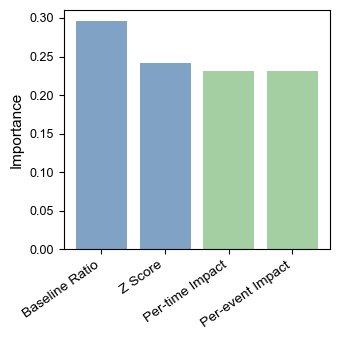

In [10]:
# Plot feature importance for the mixture classifier.

feature_importance_data = pd.DataFrame({
    "Feature": FEATURE_NAMES,
    "Importance":
        mixture_classifier.feature_importances_,
})

feature_category = {
    "Baseline Ratio": "Local",
    "Z Score": "Local",
    "Per-event Impact": "Global",
    "Per-time Impact": "Global",
}

feature_importance_data["Category"] = (
    feature_importance_data["Feature"]
    .map(feature_category)
)

feature_importance_data = (
    feature_importance_data
    .sort_values(
        "Importance",
        ascending=False,
    )
    .reset_index(drop=True)
)

feature_importance_data.to_csv(
    OUTPUT_DIR
    / "mixture_classifier_feature_importance.csv",
    index=False,
)

LOCAL_COLOR = "#80A2C5"
GLOBAL_COLOR = "#A3CFA2"

bar_colors = (
    feature_importance_data["Category"]
    .map({
        "Local": LOCAL_COLOR,
        "Global": GLOBAL_COLOR,
    })
    .tolist()
)

plt.figure(figsize=(3.5, 3.5))

plt.bar(
    feature_importance_data["Feature"],
    feature_importance_data["Importance"],
    color=bar_colors,
    edgecolor="none",
)

plt.xlabel("")

plt.ylabel(
    "Importance",
    fontsize=11,
    fontfamily="Arial",
)

plt.xticks(
    rotation=35,
    ha="right",
    fontsize=10,
    fontfamily="Arial",
)

plt.yticks(
    fontsize=9,
    fontfamily="Arial",
)

ax = plt.gca()
ax.spines["top"].set_visible(True)
ax.spines["right"].set_visible(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    / "mixture_classifier_feature_importance.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()